#Tugas 3: Polynomial Regression

##Library

In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

##Data preparation

In [18]:
df = pd.read_csv('TS.csv', header=None)
df = df.iloc[:, :2]
df.columns = ['X', 'y']
df = df.dropna()

In [19]:
df = df.sort_values(by='X')

X = df[['X']]
y = df['y']

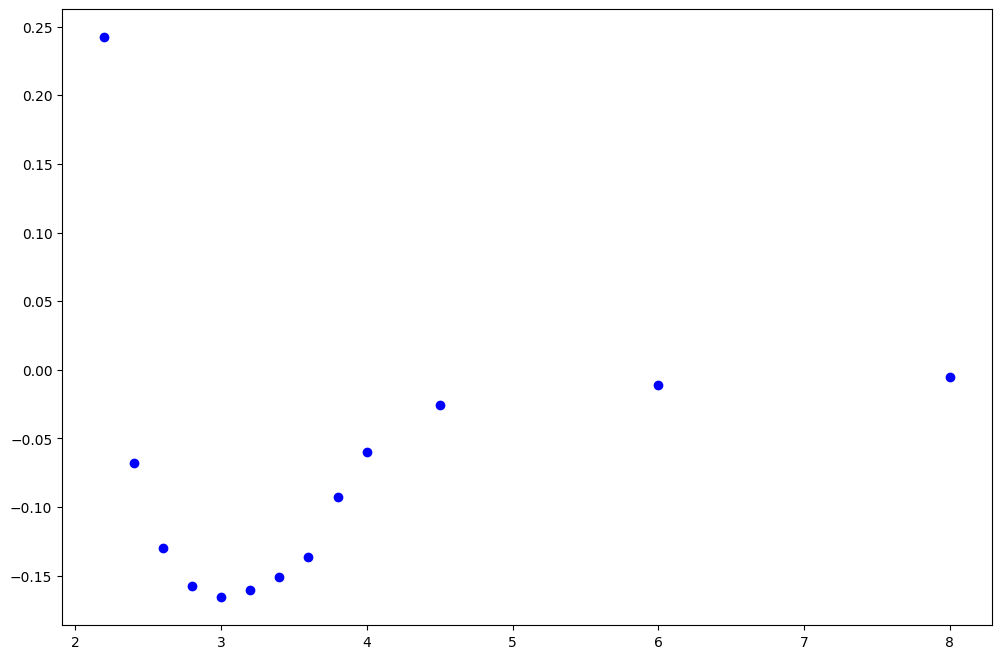

In [20]:
plt.figure(figsize=(12, 8))
plt.scatter(X, y, label='Data Asli', color='blue')

##Polynomial Fitting

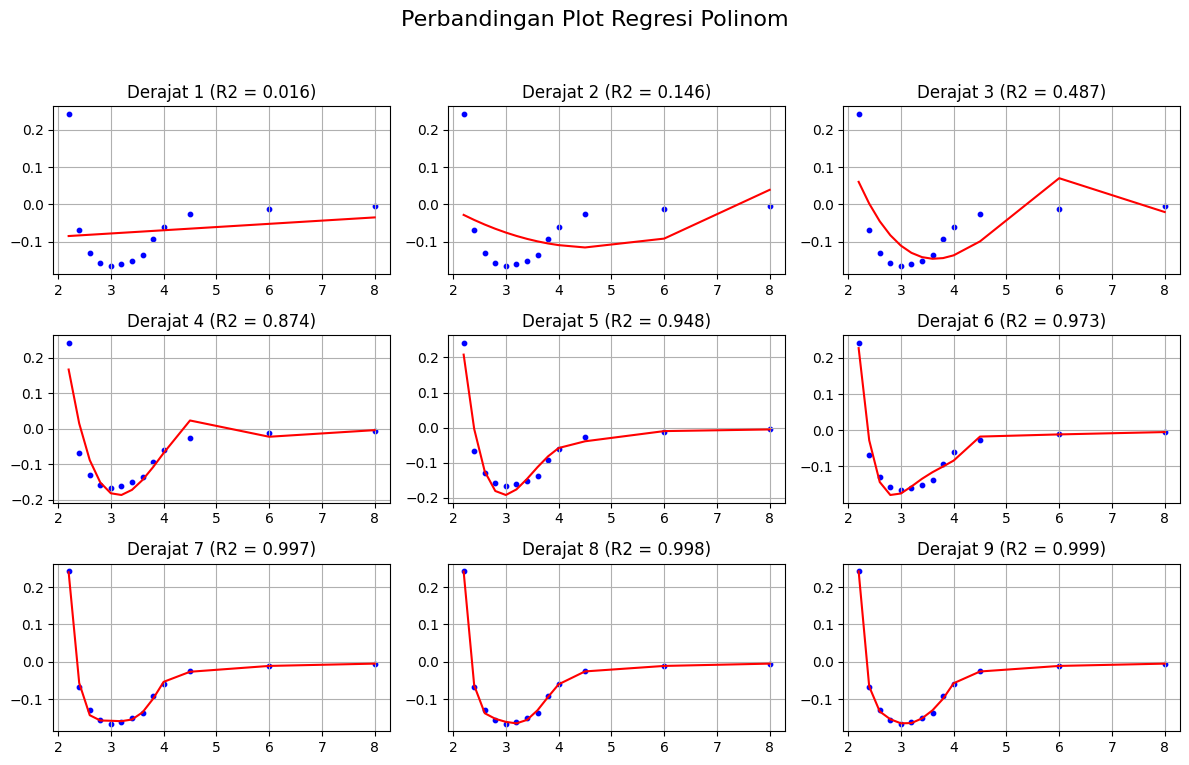

In [21]:
degrees = [1, 2, 3, 4, 5, 6, 7, 8, 9]
r2_scores = []
mae_scores = []
rmse_scores = []

fig_regresi, axs_regresi = plt.subplots(3, 3, figsize=(12, 8))
axs_regresi = axs_regresi.flatten()

for i, degree in enumerate(degrees):
    polynomial_features = PolynomialFeatures(degree=degree)
    X_poly = polynomial_features.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_poly_pred = model.predict(X_poly)

    r2 = r2_score(y, y_poly_pred)
    mae = mean_absolute_error(y, y_poly_pred)
    rmse = np.sqrt(mean_squared_error(y, y_poly_pred))

    r2_scores.append(r2)
    mae_scores.append(mae)
    rmse_scores.append(rmse)

    ax = axs_regresi[i]
    ax.scatter(X, y, label='Data Asli', color='blue', s=10)
    ax.plot(X, y_poly_pred, label=f'Kurva Regresi', color='red')
    ax.set_title(f'Derajat {degree} (R2 = {r2:.3f})')
    ax.grid(True)

fig_regresi.suptitle('Perbandingan Plot Regresi Polinom', fontsize=16)
fig_regresi.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('gabungan_plot_regresi.png')
plt.show()


##Metric Evaluation

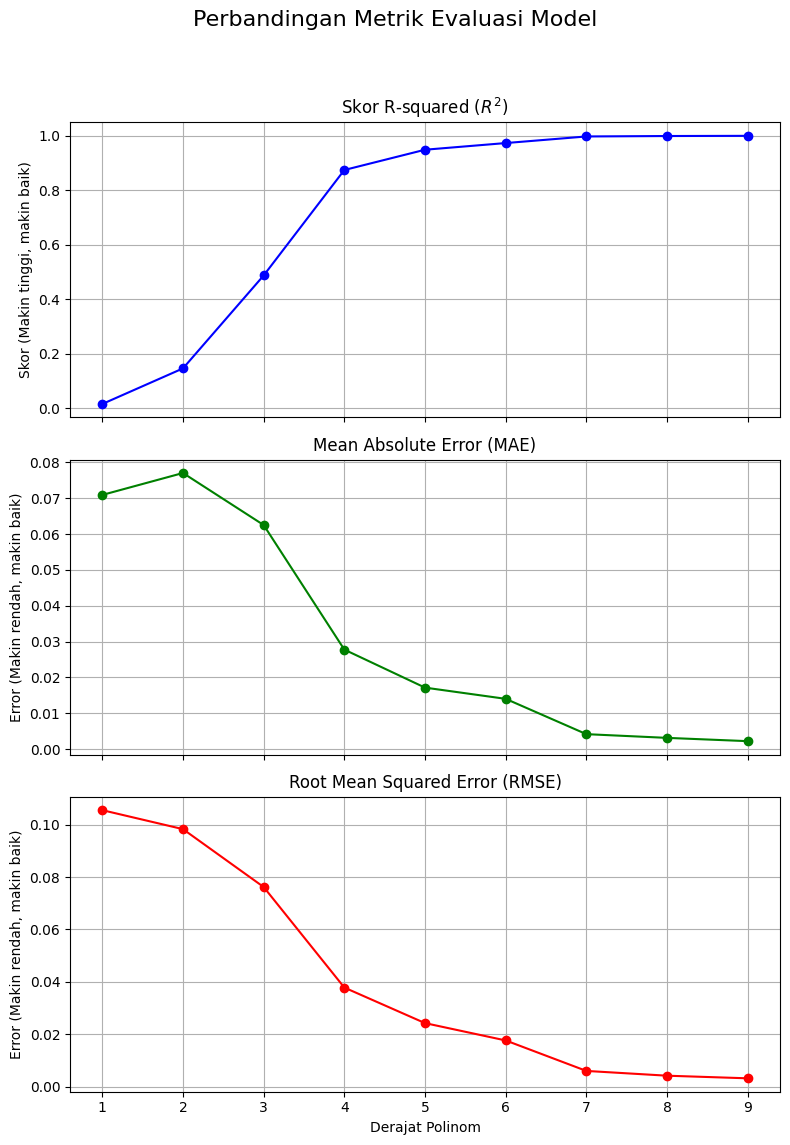

In [22]:
fig_eval, axs_eval = plt.subplots(3, 1, figsize=(8, 12), sharex=True)

# Plot R-squared
axs_eval[0].plot(degrees, r2_scores, marker='o', color='b')
axs_eval[0].set_title('Skor R-squared ($R^2$)')
axs_eval[0].set_ylabel('Skor (Makin tinggi, makin baik)')
axs_eval[0].grid(True)

# Plot MAE
axs_eval[1].plot(degrees, mae_scores, marker='o', color='g')
axs_eval[1].set_title('Mean Absolute Error (MAE)')
axs_eval[1].set_ylabel('Error (Makin rendah, makin baik)')
axs_eval[1].grid(True)

# Plot RMSE
axs_eval[2].plot(degrees, rmse_scores, marker='o', color='r')
axs_eval[2].set_title('Root Mean Squared Error (RMSE)')
axs_eval[2].set_ylabel('Error (Makin rendah, makin baik)')
axs_eval[2].set_xlabel('Derajat Polinom')
axs_eval[2].grid(True)

fig_eval.suptitle('Perbandingan Metrik Evaluasi Model', fontsize=16)
fig_eval.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('gabungan_plot_evaluasi.png')
plt.show()